## Data Understanding, Cleaning, and Exploratory Data Analysis

# STEP1: Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# STEP2: Load the dataset

In [2]:
file_path = (
    r"C:\Users\User\Desktop\DS PROJECTS\Mushroom_classification\data\mushrooms.csv"
)
mushroom_df = pd.read_csv(file_path)
mushroom_df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
mushroom_df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


# STEP3: Understand the Dataset


In [4]:
mushroom_df.info()
mushroom_df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

(8124, 23)

#3.1 Data Mapping Dictionary


In [5]:
data_dict = {
    "class": {"e": "edible", "p": "poisonous"},
    "cap-shape": {
        "b": "bell",
        "c": "conical",
        "x": "convex",
        "f": "flat",
        "k": "knobbed",
        "s": "sunken",
    },
    "cap-surface": {"f": "fibrous", "g": "grooves", "y": "scaly", "s": "smooth"},
    "cap-color": {
        "n": "brown",
        "b": "buff",
        "c": "cinnamon",
        "g": "gray",
        "r": "green",
        "p": "pink",
        "u": "purple",
        "e": "red",
        "w": "white",
        "y": "yellow",
    },
    "bruises": {"t": "bruises", "f": "does not bruise"},
    "odor": {
        "a": "almond",
        "l": "anise",
        "c": "creosote",
        "y": "fishy",
        "f": "foul",
        "m": "musty",
        "n": "none",
        "p": "pungent",
        "s": "spicy",
    },
    "gill-attachment": {
        "a": "attached",
        "d": "descending",
        "f": "free",
        "n": "notched",
    },
    "gill-spacing": {"c": "close", "w": "crowded", "d": "distant"},
    "gill-size": {"b": "broad", "n": "narrow"},
    "gill-color": {
        "k": "black",
        "n": "brown",
        "b": "buff",
        "h": "chocolate",
        "g": "gray",
        "r": "green",
        "o": "orange",
        "p": "pink",
        "u": "purple",
        "e": "red",
        "w": "white",
        "y": "yellow",
    },
    "stalk-shape": {"e": "enlarging", "t": "tapering"},
    "stalk-root": {
        "b": "bulbous",
        "c": "club",
        "u": "cup",
        "e": "equal",
        "z": "rhizomorphs",
        "r": "rooted",
        "?": "missing",
    },
    "stalk-surface-above-ring": {
        "f": "fibrous",
        "y": "scaly",
        "k": "silky",
        "s": "smooth",
    },
    "stalk-surface-below-ring": {
        "f": "fibrous",
        "y": "scaly",
        "k": "silky",
        "s": "smooth",
    },
    "stalk-color-above-ring": {
        "n": "brown",
        "b": "buff",
        "c": "cinnamon",
        "g": "gray",
        "o": "orange",
        "p": "pink",
        "e": "red",
        "w": "white",
        "y": "yellow",
    },
    "stalk-color-below-ring": {
        "n": "brown",
        "b": "buff",
        "c": "cinnamon",
        "g": "gray",
        "o": "orange",
        "p": "pink",
        "e": "red",
        "w": "white",
        "y": "yellow",
    },
    "veil-type": {"p": "partial", "u": "universal"},
    "veil-color": {"n": "brown", "o": "orange", "w": "white", "y": "yellow"},
    "ring-number": {"n": "none", "o": "one", "t": "two"},
    "ring-type": {
        "c": "cobwebby",
        "e": "evanescent",
        "f": "flaring",
        "l": "large",
        "n": "none",
        "p": "pendant",
        "s": "sheathing",
        "z": "zone",
    },
    "spore-print-color": {
        "k": "black",
        "n": "brown",
        "b": "buff",
        "h": "chocolate",
        "r": "green",
        "o": "orange",
        "u": "purple",
        "w": "white",
        "y": "yellow",
    },
    "population": {
        "a": "abundant",
        "c": "clustered",
        "n": "numerous",
        "s": "scattered",
        "v": "several",
        "y": "solitary",
    },
    "habitat": {
        "g": "grasses",
        "l": "leaves",
        "m": "meadows",
        "p": "paths",
        "u": "urban",
        "w": "waste",
        "d": "woods",
    },
}

#STEP3.1.1: Check actual categories


In [6]:
for column in mushroom_df.columns:
    print(f"\n{column}:")
    print(mushroom_df[column].unique())


class:
['p' 'e']

cap-shape:
['x' 'b' 's' 'f' 'k' 'c']

cap-surface:
['s' 'y' 'f' 'g']

cap-color:
['n' 'y' 'w' 'g' 'e' 'p' 'b' 'u' 'c' 'r']

bruises:
['t' 'f']

odor:
['p' 'a' 'l' 'n' 'f' 'c' 'y' 's' 'm']

gill-attachment:
['f' 'a']

gill-spacing:
['c' 'w']

gill-size:
['n' 'b']

gill-color:
['k' 'n' 'g' 'p' 'w' 'h' 'u' 'e' 'b' 'r' 'y' 'o']

stalk-shape:
['e' 't']

stalk-root:
['e' 'c' 'b' 'r' '?']

stalk-surface-above-ring:
['s' 'f' 'k' 'y']

stalk-surface-below-ring:
['s' 'f' 'y' 'k']

stalk-color-above-ring:
['w' 'g' 'p' 'n' 'b' 'e' 'o' 'c' 'y']

stalk-color-below-ring:
['w' 'p' 'g' 'b' 'n' 'e' 'y' 'o' 'c']

veil-type:
['p']

veil-color:
['w' 'n' 'o' 'y']

ring-number:
['o' 't' 'n']

ring-type:
['p' 'e' 'l' 'f' 'n']

spore-print-color:
['k' 'n' 'u' 'h' 'w' 'r' 'o' 'y' 'b']

population:
['s' 'n' 'a' 'v' 'y' 'c']

habitat:
['u' 'g' 'm' 'd' 'p' 'w' 'l']


In [ ]:
# STEP3.1.2 Check whether our dictionary covers every value

for column in mushroom_df.columns:
    actual_values = set(mushroom_df[column].unique())
    mapped_values = set(data_dict[column].keys())

    missing_mapping = actual_values - mapped_values

    if missing_mapping:
        print(column, "→ Missing mappings:", missing_mapping)

# STEP4: EXPLORATORY DATA ANALYSIS

#4.1 Check for data issues


In [8]:
mushroom_df.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [9]:
mushroom_df.isin(["?"]).sum()

class                          0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64

#4.2 Check duplicates


In [10]:
mushroom_df.duplicated().sum()

np.int64(0)

#4.3 Check unique values

In [11]:
mushroom_df.nunique()

class                        2
cap-shape                    6
cap-surface                  4
cap-color                   10
bruises                      2
odor                         9
gill-attachment              2
gill-spacing                 2
gill-size                    2
gill-color                  12
stalk-shape                  2
stalk-root                   5
stalk-surface-above-ring     4
stalk-surface-below-ring     4
stalk-color-above-ring       9
stalk-color-below-ring       9
veil-type                    1
veil-color                   4
ring-number                  3
ring-type                    5
spore-print-color            9
population                   6
habitat                      7
dtype: int64

#4.4 Check for constant columns: If a column has only one unique value, it provides no useful information for distinguishing classes.


In [12]:
for column in mushroom_df.columns:
    if mushroom_df[column].nunique() == 1:
        print(column)

veil-type


#4.5 Check the target distribution


In [13]:
mushroom_df["class"].value_counts()

class
e    4208
p    3916
Name: count, dtype: int64

# STEP5: DATA CLEANING

In [14]:
mushroom_df["stalk-root"].value_counts(dropna=False)

stalk-root
b    3776
?    2480
e    1120
c     556
r     192
Name: count, dtype: int64

In [15]:
mushroom_df[mushroom_df["stalk-root"] == "?"]["class"].value_counts()

class
p    1760
e     720
Name: count, dtype: int64

In [16]:
mushroom_df["class"].value_counts(normalize=True) * 100

class
e    51.797144
p    48.202856
Name: proportion, dtype: float64

#5.1 replace ? with unknown

In [ ]:
mushroom_df["stalk-root"] = mushroom_df["stalk-root"].replace("?", "unknown")
mushroom_df["stalk-root"].value_counts()

stalk-root
b          3776
unknown    2480
e          1120
c           556
r           192
Name: count, dtype: int64

#step5.2: remove veil-type

In [18]:
mushroom_df.drop("veil-type", axis=1, inplace=True)

In [19]:
mushroom_df.shape

(8124, 22)

#step5.3: verify our cleaning

In [20]:
print(mushroom_df.isnull().sum().sum())
print(mushroom_df.isin(["?"]).sum().sum())
print(mushroom_df.duplicated().sum().sum())

0
0
0


# STEP6: Prepare X and y

In [ ]:
X = mushroom_df.drop("class", axis=1)
y = mushroom_df["class"]

In [22]:
X.head()

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,s,w,w,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,s,w,w,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,s,w,w,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,s,w,w,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,s,w,w,w,o,e,n,a,g


In [23]:
print(y.head())
y.value_counts()

0    p
1    e
2    e
3    p
4    e
Name: class, dtype: object


class
e    4208
p    3916
Name: count, dtype: int64

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (8124, 21)
y shape: (8124,)


# STEP7: DATA PROFILING

In [25]:
mushroom_df.to_csv("data/mushroom_dataset_cleaned", index=False)

# Report generated using Colab

# STEP8: EDA VISUALIZATIONS

In [ ]:
mushroom_palette = {"Edible": "#422D26FF", "Poisonous": "#AB282895"}

#STEP8.1: Target Variable Distribution

In [ ]:
class_labels = {"e": "Edible", "p": "Poisonous"}

plot_df = mushroom_df.copy()
plot_df["class"] = plot_df["class"].map(class_labels)

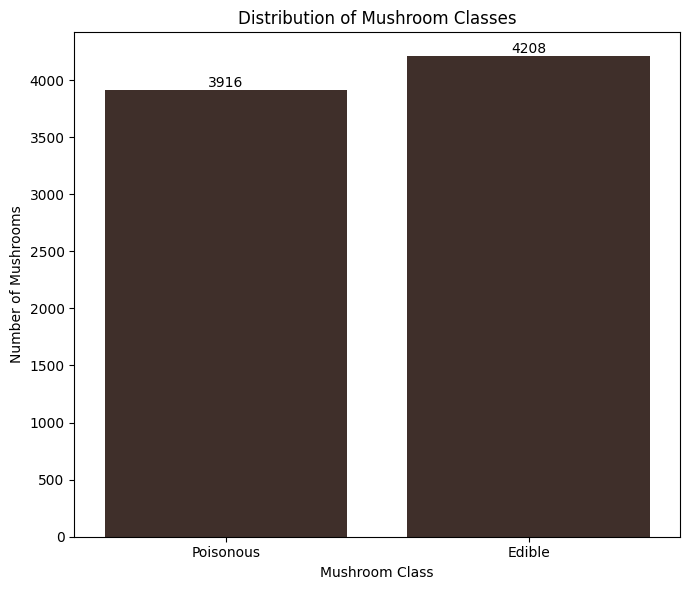

In [28]:
fig, ax = plt.subplots(figsize=(7, 6))

sns.countplot(data=plot_df, x="class", ax=ax, color=mushroom_palette["Edible"])

ax.set_title("Distribution of Mushroom Classes")
ax.set_xlabel("Mushroom Class")
ax.set_ylabel("Number of Mushrooms")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [29]:
mushroom_df.groupby(["odor", "class"]).size()

odor  class
a     e         400
c     p         192
f     p        2160
l     e         400
m     p          36
n     e        3408
      p         120
p     p         256
s     p         576
y     p         576
dtype: int64

#STEP8.2 : Odor vs Mushroom Class

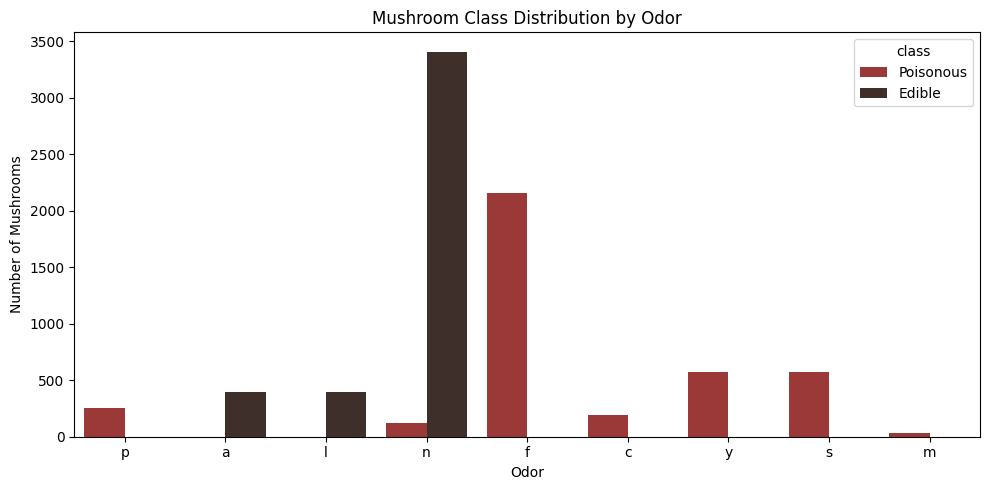

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.countplot(data=plot_df, x="odor", hue="class", ax=ax, palette=mushroom_palette)

ax.set_title("Mushroom Class Distribution by Odor")
ax.set_xlabel("Odor")
ax.set_ylabel("Number of Mushrooms")

plt.tight_layout()
plt.show()

#Chart 8.3 — Cap shape vs. Mushroom class

In [31]:
mushroom_df.groupby(["cap-shape", "class"]).size()

cap-shape  class
b          e         404
           p          48
c          p           4
f          e        1596
           p        1556
k          e         228
           p         600
s          e          32
x          e        1948
           p        1708
dtype: int64

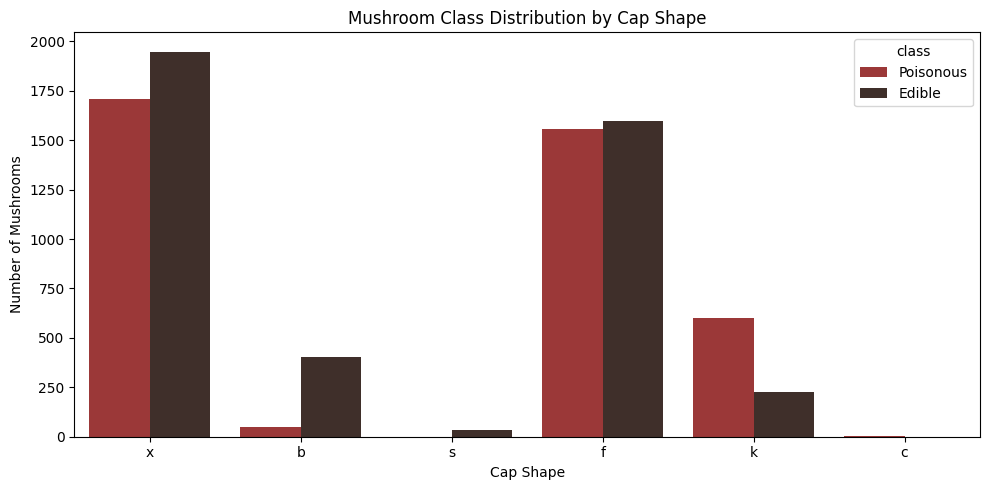

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.countplot(data=plot_df, x="cap-shape", hue="class", ax=ax, palette=mushroom_palette)

ax.set_title("Mushroom Class Distribution by Cap Shape")
ax.set_xlabel("Cap Shape")
ax.set_ylabel("Number of Mushrooms")
plt.tight_layout()
plt.show()

#Chart 8.4 — gill-color vs. Mushroom class

In [33]:
mushroom_df.groupby(["gill-color", "class"]).size()

gill-color  class
b           p        1728
e           e          96
g           e         248
            p         504
h           e         204
            p         528
k           e         344
            p          64
n           e         936
            p         112
o           e          64
p           e         852
            p         640
r           p          24
u           e         444
            p          48
w           e         956
            p         246
y           e          64
            p          22
dtype: int64

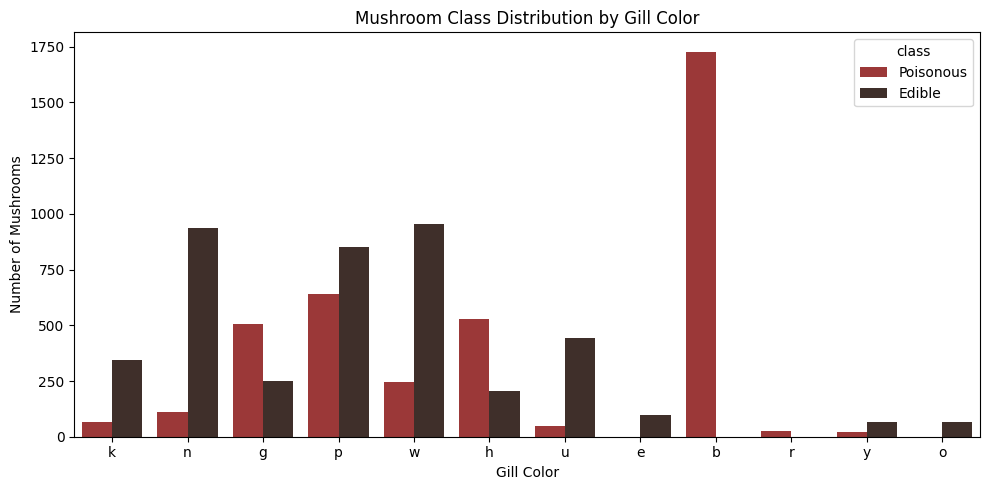

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.countplot(
    data=plot_df, x="gill-color", hue="class", ax=ax, palette=mushroom_palette
)

ax.set_title("Mushroom Class Distribution by Gill Color")
ax.set_xlabel("Gill Color")
ax.set_ylabel("Number of Mushrooms")

plt.tight_layout()
plt.show()

#Step8.5:- Cap surface vs mushroom class

In [35]:
mushroom_df.groupby(["cap-surface", "class"]).size()

cap-surface  class
f            e        1560
             p         760
g            p           4
s            e        1144
             p        1412
y            e        1504
             p        1740
dtype: int64

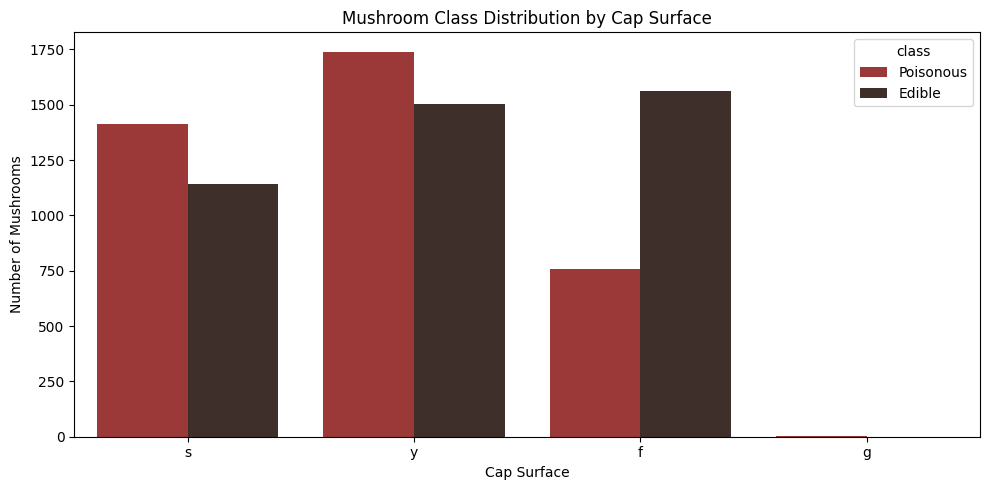

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.countplot(
    data=plot_df, x="cap-surface", hue="class", ax=ax, palette=mushroom_palette
)

ax.set_title("Mushroom Class Distribution by Cap Surface")
ax.set_xlabel("Cap Surface")
ax.set_ylabel("Number of Mushrooms")

plt.tight_layout()
plt.show()

#Step8.6:-Cap color vs mushroom class

In [ ]:
mushroom_df.groupby(["cap-color", "class"]).size()

cap-color  class
b          e          48
           p         120
c          e          32
           p          12
e          e         624
           p         876
g          e        1032
           p         808
n          e        1264
           p        1020
p          e          56
           p          88
r          e          16
u          e          16
w          e         720
           p         320
y          e         400
           p         672
dtype: int64

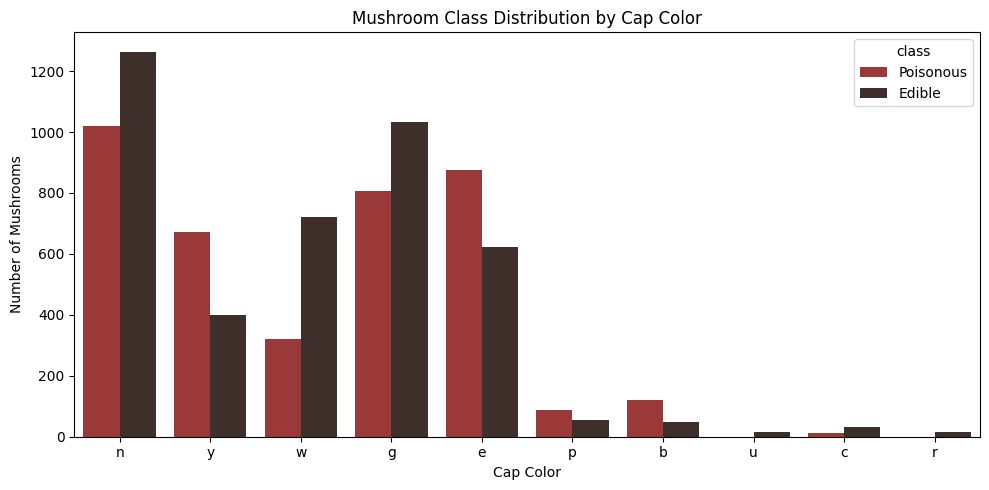

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.countplot(data=plot_df, x="cap-color", hue="class", ax=ax, palette=mushroom_palette)

ax.set_title("Mushroom Class Distribution by Cap Color")
ax.set_xlabel("Cap Color")
ax.set_ylabel("Number of Mushrooms")

plt.tight_layout()
plt.show()

#Step8.7:- Bruises vs mushroom class

In [ ]:
mushroom_df.groupby(["bruises", "class"]).size()

bruises  class
f        e        1456
         p        3292
t        e        2752
         p         624
dtype: int64

C:\Users\User\AppData\Local\Temp\ipykernel_15876\2562603120.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["No Bruises", "Bruises Present"])


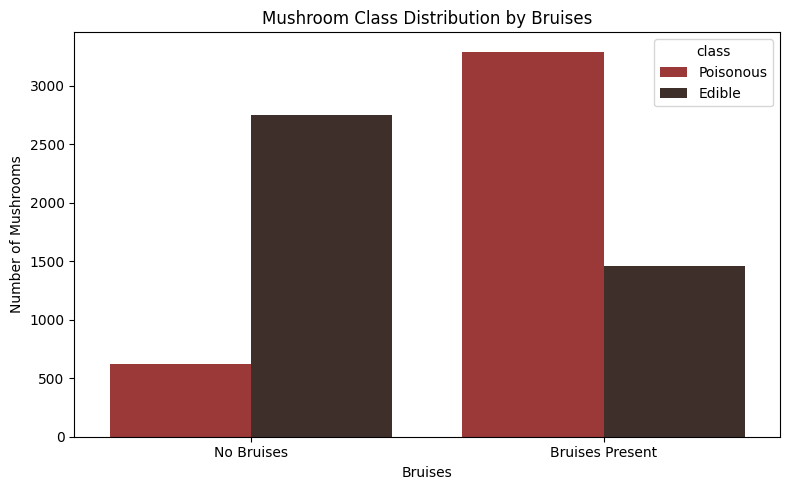

In [40]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=plot_df,
    x="bruises",
    hue="class",
    palette=mushroom_palette,
    order=["t", "f"],
    ax=ax,
)

ax.set_title("Mushroom Class Distribution by Bruises")
ax.set_xlabel("Bruises")
ax.set_ylabel("Number of Mushrooms")
ax.set_xticklabels(["No Bruises", "Bruises Present"])

plt.tight_layout()
plt.show()

#Step8.8:- Gill attachment vs. mushroom class

In [ ]:
mushroom_df.groupby(["gill-attachment", "class"]).size()

gill-attachment  class
a                e         192
                 p          18
f                e        4016
                 p        3898
dtype: int64

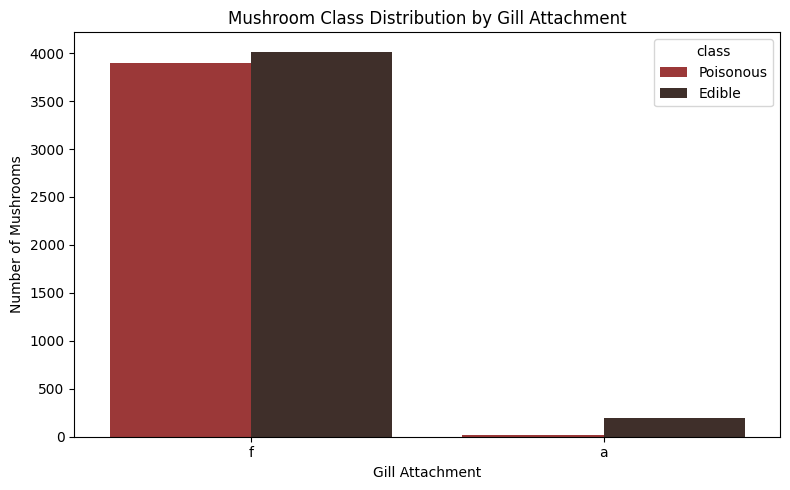

In [42]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=plot_df, x="gill-attachment", hue="class", palette=mushroom_palette, ax=ax
)

ax.set_title("Mushroom Class Distribution by Gill Attachment")
ax.set_xlabel("Gill Attachment")
ax.set_ylabel("Number of Mushrooms")

plt.tight_layout()
plt.show()

#STEP8.9:-Final Data Checks

In [43]:
print("Dataset shape:", mushroom_df.shape)
print("\nMissing values:", mushroom_df.isnull().sum().sum())
print("\nRemaining '?' values:", (mushroom_df == "?").sum().sum())
print("\nDuplicate rows:", mushroom_df.duplicated().sum())
print("\nTarget distribution:\n", mushroom_df["class"].value_counts())

Dataset shape: (8124, 22)

Missing values: 0

Remaining '?' values: 0

Duplicate rows: 0

Target distribution:
 class
e    4208
p    3916
Name: count, dtype: int64


## Feature–Target Separation and Train/Test Split

## STEP 9: TRAIN-TEST SPLIT

In [44]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = mushroom_df.drop("class", axis=1)
y = mushroom_df["class"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (6499, 21)
X_test shape: (1625, 21)
y_train shape: (6499,)
y_test shape: (1625,)


## Step 10: Import the required libraries

In [45]:
# Data handling
import pandas as pd

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Pipeline and cross-validation
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import accuracy_score, classification_report

# Saving trained models
import joblib

## Model Development and Evaluation

## Step 1: Identify categorical features

In [99]:
# Identify categorical columns
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

# Display the results
print("Number of categorical features:", len(categorical_features))
print(categorical_features)

Number of categorical features: 21
['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']


## Step 2:- Create the ColumnTransformer

In [49]:
# Create the OneHotEncoder
categorical_encoder = OneHotEncoder(handle_unknown="ignore")

# Create the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[("cat", categorical_encoder, categorical_features)]
)

In [50]:
print(preprocessor)

ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['cap-shape', 'cap-surface', 'cap-color',
                                  'bruises', 'odor', 'gill-attachment',
                                  'gill-spacing', 'gill-size', 'gill-color',
                                  'stalk-shape', 'stalk-root',
                                  'stalk-surface-above-ring',
                                  'stalk-surface-below-ring',
                                  'stalk-color-above-ring',
                                  'stalk-color-below-ring', 'veil-color',
                                  'ring-number', 'ring-type',
                                  'spore-print-color', 'population',
                                  'habitat'])])


## Step 4:- Build Machine Learning Pipelines

In [51]:
# Logistic Regression pipeline
lr_pipeline = Pipeline(
    [("preprocessor", preprocessor), ("model", LogisticRegression(max_iter=1000))]
)

# Support Vector Classifier pipeline
svc_pipeline = Pipeline([("preprocessor", preprocessor), ("model", SVC())])

# K-Nearest Neighbors pipeline
knn_pipeline = Pipeline(
    [("preprocessor", preprocessor), ("model", KNeighborsClassifier())]
)

# Random Forest pipeline
rf_pipeline = Pipeline(
    [("preprocessor", preprocessor), ("model", RandomForestClassifier(random_state=42))]
)

## Step 5:- Hyperparameter Tuning Using GridSearchCV

In [52]:
lr_param_grid = {"model__C": [0.1, 1, 10]}

In [53]:
svc_param_grid = {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"]}

In [ ]:
knn_param_grid = {"model__n_neighbors": [3, 5, 7, 9]}

In [55]:
rf_param_grid = {"model__n_estimators": [100, 200], "model__max_depth": [None, 10, 20]}

## Step 6:- Initialize GridSearchCV for Each Model

In [56]:
# Logistic Regression Grid Search
lr_grid_search = GridSearchCV(
    estimator=lr_pipeline, param_grid=lr_param_grid, cv=5, scoring="accuracy", n_jobs=-1
)

# SVC Grid Search
svc_grid_search = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=svc_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

# KNN Grid Search
knn_grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

# Random Forest Grid Search
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline, param_grid=rf_param_grid, cv=5, scoring="accuracy", n_jobs=-1
)

## Step 7:- Fit GridSearchCV on the Training Data

In [ ]:
# Tune Logistic Regression
lr_grid_search.fit(X_train, y_train)

# Tune SVC
svc_grid_search.fit(X_train, y_train)

# Tune KNN
knn_grid_search.fit(X_train, y_train)

# Tune Random Forest
rf_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is a

## Step 8:- Best Hyperparameters and Cross-Validation Scores

In [58]:
# Display the best parameters and CV accuracy for each model

print("Logistic Regression")
print("Best Parameters:", lr_grid_search.best_params_)
print("Best CV Accuracy:", lr_grid_search.best_score_)
print("-" * 50)

print("SVC")
print("Best Parameters:", svc_grid_search.best_params_)
print("Best CV Accuracy:", svc_grid_search.best_score_)
print("-" * 50)

print("KNN")
print("Best Parameters:", knn_grid_search.best_params_)
print("Best CV Accuracy:", knn_grid_search.best_score_)
print("-" * 50)

print("Random Forest")
print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV Accuracy:", rf_grid_search.best_score_)

Logistic Regression
Best Parameters: {'model__C': 1}
Best CV Accuracy: 0.9993846153846153
--------------------------------------------------
SVC
Best Parameters: {'model__C': 1, 'model__kernel': 'linear'}
Best CV Accuracy: 1.0
--------------------------------------------------
KNN
Best Parameters: {'model__n_neighbors': 3}
Best CV Accuracy: 0.9993846153846153
--------------------------------------------------
Random Forest
Best Parameters: {'model__max_depth': None, 'model__n_estimators': 100}
Best CV Accuracy: 1.0


## Step 9:- Model Evaluation on Test Data

In [60]:
# Get the best fitted pipelines
best_lr_model = lr_grid_search.best_estimator_
best_svc_model = svc_grid_search.best_estimator_
best_knn_model = knn_grid_search.best_estimator_
best_rf_model = rf_grid_search.best_estimator_

In [61]:
# Make predictions on the test set
y_pred_lr = best_lr_model.predict(X_test)
y_pred_svc = best_svc_model.predict(X_test)
y_pred_knn = best_knn_model.predict(X_test)
y_pred_rf = best_rf_model.predict(X_test)

In [62]:
print("Actual classes:", y_test.head().tolist())
print("Predicted classes:", y_pred_lr[:5])

Actual classes: ['p', 'p', 'e', 'p', 'p']
Predicted classes: ['p' 'p' 'e' 'p' 'p']


In [63]:
# Evaluate test accuracy for all four models

print("Logistic Regression Test Accuracy:", accuracy_score(y_test, y_pred_lr))

print("SVC Test Accuracy:", accuracy_score(y_test, y_pred_svc))

print("KNN Test Accuracy:", accuracy_score(y_test, y_pred_knn))

print("Random Forest Test Accuracy:", accuracy_score(y_test, y_pred_rf))

Logistic Regression Test Accuracy: 0.9993846153846154
SVC Test Accuracy: 1.0
KNN Test Accuracy: 1.0
Random Forest Test Accuracy: 1.0


In [68]:
# LR
print("Logistic Regression Classification Report")
print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=["e", "p"],
        target_names=["Edible", "Poisonous"],
        digits=4,
    )
)
print("-" * 60)

# SVC
print("SVC Classification Report")
print(
    classification_report(
        y_test,
        y_pred_svc,
        labels=["e", "p"],
        target_names=["Edible", "Poisonous"],
        digits=4,
    )
)
print("-" * 60)

# KNN
print("KNN Classification Report")
print(
    classification_report(
        y_test,
        y_pred_knn,
        labels=["e", "p"],
        target_names=["Edible", "Poisonous"],
        digits=4,
    )
)
print("-" * 60)

# Random Forest
print("Random Forest Classification Report")
print(
    classification_report(
        y_test,
        y_pred_rf,
        labels=["e", "p"],
        target_names=["Edible", "Poisonous"],
        digits=4,
    )
)

Logistic Regression Classification Report
              precision    recall  f1-score   support

      Edible     0.9988    1.0000    0.9994       842
   Poisonous     1.0000    0.9987    0.9994       783

    accuracy                         0.9994      1625
   macro avg     0.9994    0.9994    0.9994      1625
weighted avg     0.9994    0.9994    0.9994      1625

------------------------------------------------------------
SVC Classification Report
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625

------------------------------------------------------------
KNN Classification Report
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.00

## Step 10:- The Model Comparison Table

In [ ]:
# Create a comparison table for all four models

results = pd.DataFrame(
    {
        "Model": ["Logistic Regression", "SVC", "KNN", "Random Forest"],
        "Test Accuracy": [
            accuracy_score(y_test, y_pred_lr),
            accuracy_score(y_test, y_pred_svc),
            accuracy_score(y_test, y_pred_knn),
            accuracy_score(y_test, y_pred_rf),
        ],
    }
)

# Display the results as percentages
results["Test Accuracy (%)"] = results["Test Accuracy"] * 100
results

,Model,Test Accuracy,Test Accuracy (%)
0,Logistic Regression,0.999385,99.938462
1,SVC,1.000000,100.000000
2,KNN,1.000000,100.000000
3,Random Forest,1.000000,100.000000


## Step 11:- Visualize model performance

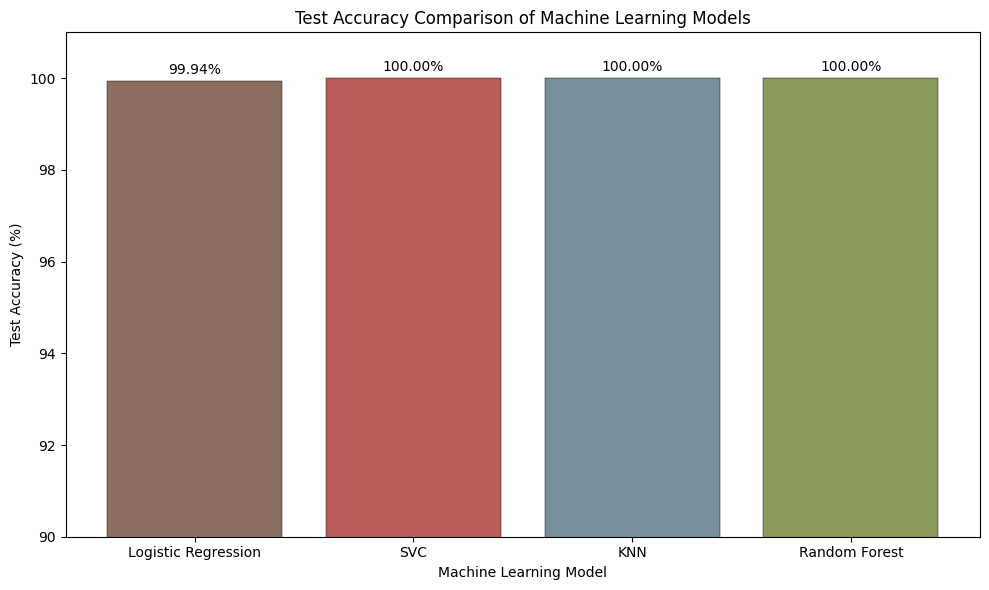

In [94]:
import matplotlib.pyplot as plt

# Define colors for each model
model_colors = [
    "#8D6E63",  # Logistic Regression
    "#B85C5C",  # SVC
    "#78909C",  # KNN
    "#8A9A5B",  # Random Forest
]
# Create a bar chart for model comparison
plt.figure(figsize=(10, 6))

bars= plt.bar(
    results["Model"],
    results["Test Accuracy (%)"],
    color=model_colors,
    edgecolor="black",
    linewidth=0.3,
)

plt.title("Test Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(90, 101)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

In [95]:
import os
# Create a folder to store trained models
os.makedirs("models", exist_ok=True)

In [96]:
# Save the best fitted pipelines using Joblib

joblib.dump(best_lr_model, "models/logistic_regression_pipeline.joblib")
joblib.dump(best_svc_model, "models/svc_pipeline.joblib")
joblib.dump(best_knn_model, "models/knn_pipeline.joblib")
joblib.dump(best_rf_model, "models/random_forest_pipeline.joblib")

['models/random_forest_pipeline.joblib']

In [97]:
os.listdir("models")

['knn_pipeline.joblib',
 'logistic_regression_pipeline.joblib',
 'random_forest_pipeline.joblib',
 'svc_pipeline.joblib']

## Step 12:- Test a saved pipeline

In [100]:
# Load the saved Logistic Regression pipeline
loaded_lr_model = joblib.load("models/logistic_regression_pipeline.joblib")

In [101]:
# Make predictions with the loaded pipeline
loaded_predictions = loaded_lr_model.predict(X_test)

print("First 5 predictions:", loaded_predictions[:5])
print("Original predictions:", y_pred_lr[:5])

First 5 predictions: ['p' 'p' 'e' 'p' 'p']
Original predictions: ['p' 'p' 'e' 'p' 'p']
